# 🎓 Early Warning: Predicting Which Students Need Help

**Author:** Joanne
**Mission 1 — IEEE WIE Technical Domain**

---

## 1. The Idea

**What does the model predict?**
After the **first term**, can we predict whether a student will **pass or fail** the final maths exam?
The model looks at the student's first-term grade, attendance (absences), past failures, study habits and background, and predicts **pass** (final grade ≥ 10 out of 20) or **fail**.

**Why is this useful?**
- If a teacher finds out a student is failing only *after* the final exam, it's too late to help.
- An **early warning** after the first term gives teachers months to step in: extra classes, mentoring, or a conversation about what's going wrong.
- It connects to my hardware project **SmartAttend**, an RFID attendance system. Collecting attendance data is only useful if it helps someone act. This project asks: *does attendance actually predict results?*

<!-- ✏️ CUSTOMIZE: add a line about why this matters to you personally -->

**Dataset:** UCI Student Performance (Maths) — 395 students from two Portuguese secondary schools, 33 columns.
Source: https://archive.ics.uci.edu/dataset/320/student+performance

## 2. Data Preparation

### 2.1 Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixed seed so results are identical every run
PASS_COLOR, FAIL_COLOR = "#2a9d8f", "#e76f51"

### 2.2 Load the dataset

In [2]:
LOCAL_PATH = "data/student-mat.csv"
URL = "https://raw.githubusercontent.com/arunk13/MSDA-Assignments/master/IS607Fall2015/Assignment3/student-mat.csv"

try:
    df = pd.read_csv(LOCAL_PATH, sep=";")     # this file uses ; instead of , between values
    print("Loaded from local file")
except FileNotFoundError:
    df = pd.read_csv(URL, sep=";")
    print("Loaded from URL")

print("Shape:", df.shape)
df.head()

Loaded from local file
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Each row is one student. The columns I care about most:

| Column | Meaning |
|---|---|
| `G1`, `G2`, `G3` | Grades for term 1, term 2 and the **final** grade (0–20) |
| `absences` | Number of school days missed (0–93) |
| `failures` | Number of classes failed in the past (0–3) |
| `studytime` | Weekly study time (1 = <2 hrs, 2 = 2–5 hrs, 3 = 5–10 hrs, 4 = >10 hrs) |
| `higher` | Does the student want to go on to higher education? (yes/no) |
| `goout`, `freetime` | Going out with friends / free time (1 = very low … 5 = very high) |

### 2.3 Create the target: pass or fail

passed
Pass    265
Fail    130
Name: count, dtype: int64

Pass rate: 67.1%


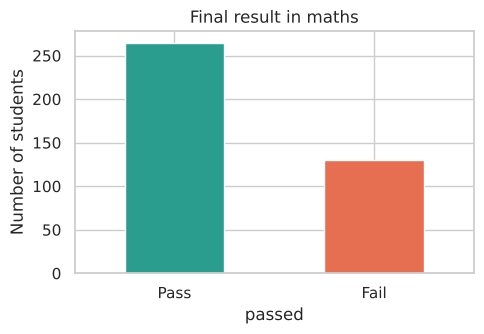

In [3]:
df["passed"] = (df["G3"] >= 10).astype(int)     # 1 = pass, 0 = fail (10/20 is the pass mark in Portugal)

counts = df["passed"].map({1: "Pass", 0: "Fail"}).value_counts()
print(counts)
print(f"\nPass rate: {df['passed'].mean():.1%}")

ax = counts.plot(kind="bar", color=[PASS_COLOR, FAIL_COLOR], rot=0, figsize=(5, 3.5))
ax.set_title("Final result in maths")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.show()

**67% of students pass.** This number matters a lot: a "lazy model" that just says *everyone passes* would already be **67% accurate**. That's my **baseline**. A useful model has to clearly beat it.

### 2.4 Check for missing values

In [4]:
print("Missing values per column (only columns with any):")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None — the dataset is complete")

Missing values per column (only columns with any):
None — the dataset is complete


### 2.5 Investigating a mystery: the students who scored 0
While exploring, I noticed something strange: students with **zero absences** seemed to fail *more* often than students who missed a few days. That doesn't make sense, so I dug in.

In [5]:
zero = df[df["G3"] == 0]
print("Students with a final grade of 0:", len(zero))
print("...of whom have 0 absences:", (zero["absences"] == 0).sum())
print(f"...their average 1st-term grade: {zero['G1'].mean():.1f} / 20")

Students with a final grade of 0: 38
...of whom have 0 absences: 38
...their average 1st-term grade: 7.5 / 20


**All 38 students with a final grade of 0 also have 0 absences.** A real student who scored 0 would almost certainly have missed *some* days. These students most likely **dropped out or didn't sit the final exam**, so the school recorded 0 for both values. Their first-term grades (average 7.5) show they were real students who were already struggling.

**My decision:** keep them in the data as **fails**. An early-warning system *should* learn to spot students at risk of dropping out. But their `absences = 0` isn't real attendance data, so I leave them out when I look at the attendance pattern below.

### 2.6 Does attendance predict results?

absence_group
0 days          84%
1–5 days        78%
6–10 days       74%
more than 10    55%
Name: passed, dtype: str


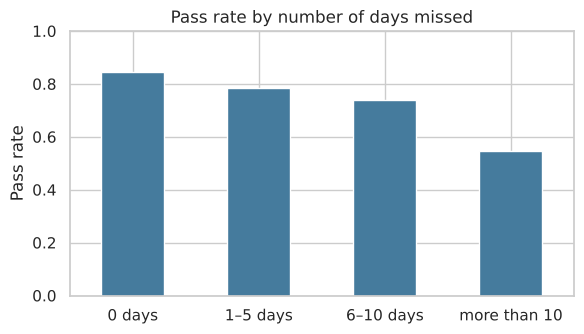

In [6]:
attending = df[df["G3"] > 0].copy()     # exclude the 38 likely dropouts (their absences look unrecorded)
attending["absence_group"] = pd.cut(attending["absences"], bins=[-1, 0, 5, 10, 100],
                                    labels=["0 days", "1–5 days", "6–10 days", "more than 10"])
rate = attending.groupby("absence_group", observed=True)["passed"].mean()
print(rate.map("{:.0%}".format))

ax = rate.plot(kind="bar", color="#457b9d", rot=0, figsize=(6, 3.5))
ax.set_title("Pass rate by number of days missed")
ax.set_ylabel("Pass rate")
ax.set_xlabel("")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Clear pattern: the more days a student misses, the less likely they are to pass.** It falls from 84% (no absences) to 55% (more than 10).
This is the evidence behind attendance tracking: students who start missing school are students who need attention.

### 2.7 Other warning signs

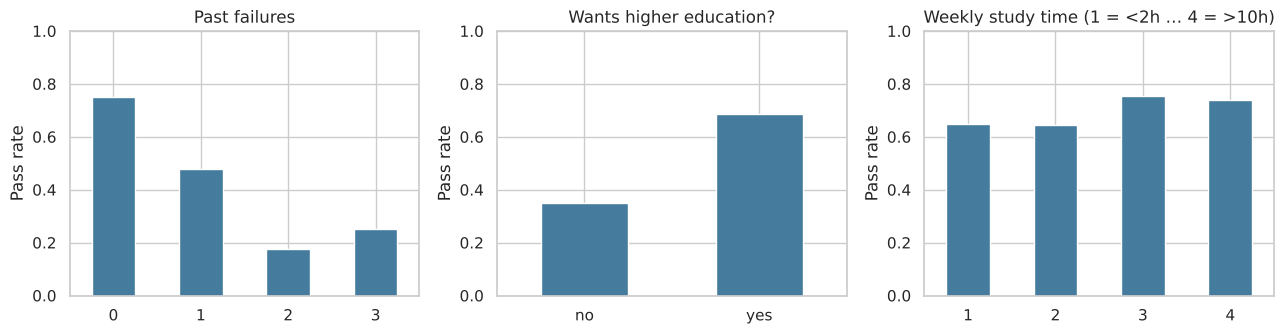

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

df.groupby("failures")["passed"].mean().plot(kind="bar", ax=axes[0], color="#457b9d", rot=0)
axes[0].set_title("Past failures")

df.groupby("higher")["passed"].mean().plot(kind="bar", ax=axes[1], color="#457b9d", rot=0)
axes[1].set_title("Wants higher education?")

df.groupby("studytime")["passed"].mean().plot(kind="bar", ax=axes[2], color="#457b9d", rot=0)
axes[2].set_title("Weekly study time (1 = <2h … 4 = >10h)")

for ax in axes:
    ax.set_ylim(0, 1); ax.set_ylabel("Pass rate"); ax.set_xlabel("")
plt.tight_layout()
plt.show()

- **Past failures** are a strong signal: 75% pass with no past failures, but only 18% with two.
- Students who **want higher education** are about twice as likely to pass.
- **Study time** helps, but less than you might expect.

### 2.8 Prepare features (X) and target (y)

**Which columns does the model get to see?**
- ❌ `G3` is the answer, so it's removed.
- ❌ `G2` (2nd-term grade) is hidden on purpose. This is an *early* warning after term 1, when the 2nd-term grade doesn't exist yet. Using it would make the model more accurate but much less useful.
- ✅ `G1` (1st-term grade) is kept, because it's known at the moment we'd make the prediction.
- ✅ Everything else is kept: attendance, past failures, habits, background.

In [8]:
y = df["passed"]
X_raw = df.drop(columns=["G3", "G2", "passed"])

# Encoding: text columns -> numbers.
# drop_first=True turns yes/no columns into a single 0/1 column (e.g. 'higher_yes')
# and turns multi-category columns (like mother's job) into one-hot columns.
X = pd.get_dummies(X_raw, drop_first=True).astype(int)

print("Columns before encoding:", X_raw.shape[1])
print("Columns after encoding: ", X.shape[1])

Columns before encoding: 31
Columns after encoding:  40


### 2.9 Split into training and test sets

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Training students:", len(X_train))
print("Test students:    ", len(X_test))

baseline = y_test.mean()
print(f"\nBaseline ('everyone passes') accuracy on the test set: {baseline:.1%}")

Training students: 316
Test students:     79

Baseline ('everyone passes') accuracy on the test set: 67.1%


The models learn from **316 students** and are tested on **79 students they've never seen**. `stratify=y` keeps the 67/33 pass/fail ratio the same in both groups.

## 3. Model Building

### Model 1 — Decision Tree 🌳
A Decision Tree learns a flowchart of yes/no questions, like *"Was the 1st-term grade ≤ 10.5?"* → *"More than 1 past failure?"* → pass/fail.

**First attempt: an unlimited tree.**

In [10]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Training accuracy: {full_tree.score(X_train, y_train):.1%}")
print(f"Test accuracy:     {full_tree.score(X_test, y_test):.1%}")
print("Tree depth:", full_tree.get_depth())

Training accuracy: 100.0%
Test accuracy:     77.2%
Tree depth: 11


**100% on training but much lower on new students: this is overfitting.** The tree grew deep enough to memorise every training student, including random quirks, instead of learning general rules.

**Fix:** limit the depth. To choose the depth *fairly*, I use **cross-validation on the training set only** (`GridSearchCV`). It tries depths 1–10, tests each on 5 different splits, and picks the best average.

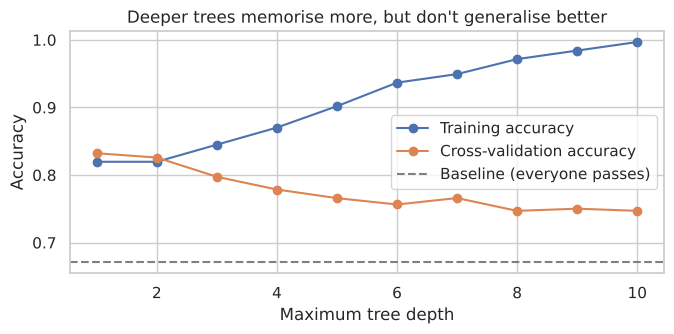

In [11]:
depths = range(1, 11)
train_scores, cv_scores = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_scores.append(tree.score(X_train, y_train))
    cv_scores.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
                                     X_train, y_train, cv=5).mean())

plt.figure(figsize=(7, 3.5))
plt.plot(depths, train_scores, marker="o", label="Training accuracy")
plt.plot(depths, cv_scores, marker="o", label="Cross-validation accuracy")
plt.axhline(baseline, ls="--", color="grey", label="Baseline (everyone passes)")
plt.title("Deeper trees memorise more, but don't generalise better")
plt.xlabel("Maximum tree depth"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout(); plt.show()

In [12]:
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         {"max_depth": list(depths)}, cv=5)
dt_search.fit(X_train, y_train)
dt_model = dt_search.best_estimator_

print("Best depth chosen by cross-validation:", dt_search.best_params_["max_depth"])
dt_pred = dt_model.predict(X_test)
dt_acc = accuracy_score(y_test, dt_pred)
print(f"Decision Tree test accuracy: {dt_acc:.1%}")

Best depth chosen by cross-validation: 1
Decision Tree test accuracy: 79.7%


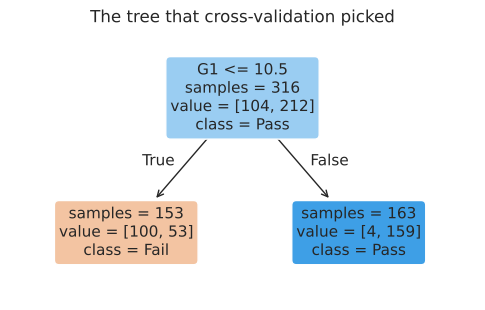

In [13]:
plt.figure(figsize=(6, 3.5))
plot_tree(dt_model, feature_names=X.columns, class_names=["Fail", "Pass"],
          filled=True, rounded=True, impurity=False, fontsize=11)
plt.title("The tree that cross-validation picked")
plt.show()

**Surprise: the best tree asks just one question, "Was the 1st-term grade ≤ 10.5?"**
In other words, *a student who is below the pass mark after term 1 is likely to fail the year.* Extra questions made the tree fit the training data better but didn't help on new students.

### Model 2 — K-Nearest Neighbors (KNN) 📍
KNN predicts by finding the **k most similar students** in the training data and taking a majority vote.
"Similar" is measured by **distance**, which brings two important details:

1. **Scaling.** `absences` ranges from 0–75 but `failures` only 0–3. Without scaling, a difference of 1 absence would count the same as 1 failure, so big-range columns would dominate. `StandardScaler` puts every column on the same scale. I wrap it in a **pipeline** so the scaler learns only from the training data.
2. **Feature choice.** KNN treats every column as equally important. Let's see what happens with all 40 columns:

In [14]:
knn_all = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_all.fit(X_train, y_train)
print(f"KNN with all {X.shape[1]} columns — test accuracy: {knn_all.score(X_test, y_test):.1%}")
print(f"Baseline:                          {baseline:.1%}")

KNN with all 40 columns — test accuracy: 68.4%
Baseline:                          67.1%


**KNN with every column is no better than the lazy baseline.** Most of the 40 columns (parents' jobs, family size, …) are weak signals, and together they drown out the few strong ones in the distance calculation.

**Fix:** give KNN only the strongest warning signs I found while exploring:
**1st-term grade, absences and past failures.** (Absences earns its place here, which is the SmartAttend connection.)

In [15]:
KNN_FEATURES = ["G1", "absences", "failures"]     # ✏️ CUSTOMIZE: try adding 'higher_yes' or 'studytime'

knn_search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                          {"kneighborsclassifier__n_neighbors": list(range(1, 31, 2))}, cv=5)
knn_search.fit(X_train[KNN_FEATURES], y_train)
knn_model = knn_search.best_estimator_
best_k = knn_search.best_params_["kneighborsclassifier__n_neighbors"]

print("Best k chosen by cross-validation:", best_k)
knn_pred = knn_model.predict(X_test[KNN_FEATURES])
knn_acc = accuracy_score(y_test, knn_pred)
print(f"KNN test accuracy: {knn_acc:.1%}")

Best k chosen by cross-validation: 11
KNN test accuracy: 81.0%


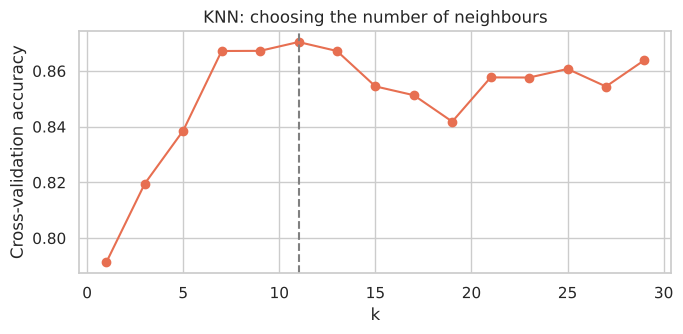

In [16]:
ks = list(range(1, 31, 2))
k_cv = knn_search.cv_results_["mean_test_score"]
plt.figure(figsize=(7, 3.5))
plt.plot(ks, k_cv, marker="o", color="#e76f51")
plt.axvline(best_k, ls="--", color="grey")
plt.title("KNN: choosing the number of neighbours")
plt.xlabel("k"); plt.ylabel("Cross-validation accuracy")
plt.tight_layout(); plt.show()

Small k (1–3) is too sensitive to individual students. Large k averages over students who aren't really similar. Cross-validation picks a value in between.

## 4. Evaluation

### 4.1 Accuracy comparison

In [17]:
dt_cv = cross_val_score(DecisionTreeClassifier(max_depth=dt_search.best_params_["max_depth"], random_state=RANDOM_STATE),
                        X, y, cv=5).mean()
knn_cv = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
                         X[KNN_FEATURES], y, cv=5).mean()

results = pd.DataFrame({
    "Model": ["Baseline (everyone passes)", "Decision Tree", f"KNN (k={best_k})"],
    "Test accuracy": [baseline, dt_acc, knn_acc],
    "5-fold CV accuracy": [np.nan, dt_cv, knn_cv],
})
results.style.format({"Test accuracy": "{:.1%}", "5-fold CV accuracy": "{:.1%}"}, na_rep="—")

,Model,Test accuracy,5-fold CV accuracy
0,Baseline (everyone passes),67.1%,—
1,Decision Tree,79.7%,81.0%
2,KNN (k=11),81.0%,86.6%


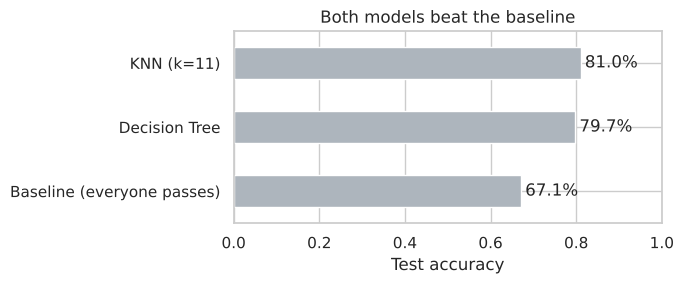

In [18]:
plot_df = results.set_index("Model")[["Test accuracy"]]
ax = plot_df.plot(kind="barh", legend=False, color=["#adb5bd", "#457b9d", "#e76f51"], figsize=(7, 3))
ax.set_xlim(0, 1); ax.set_xlabel("Test accuracy"); ax.set_ylabel("")
ax.set_title("Both models beat the baseline")
for i, v in enumerate(plot_df["Test accuracy"]):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center")
plt.tight_layout(); plt.show()

### 4.2 Confusion matrices: *which* mistakes?
For an early-warning system, the two kinds of mistake are **not equal**:

| | Predicted fail | Predicted pass |
|---|---|---|
| **Actually failed** | ✅ Caught in time | ⚠️ **Missed student**: nobody helps them |
| **Actually passed** | False alarm: a bit of extra attention | ✅ Correct |

A false alarm costs a teacher a conversation. A missed student might fail the year. So **catching failing students matters more than raw accuracy.**

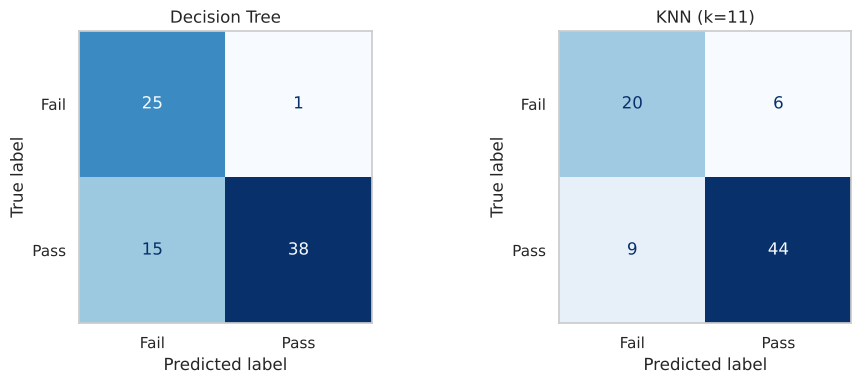

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ["Fail", "Pass"]
for ax, pred, name in zip(axes, [dt_pred, knn_pred], ["Decision Tree", f"KNN (k={best_k})"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()

In [20]:
total_fails = (y_test == 0).sum()
for name, pred in [("Decision Tree", dt_pred), (f"KNN (k={best_k})", knn_pred)]:
    # rows = actual (Fail, Pass), columns = predicted (Fail, Pass)
    caught, missed, false_alarm, correct_pass = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: caught {caught} of {total_fails} failing students, "
          f"missed {missed}, false alarms {false_alarm}")

Decision Tree: caught 25 of 26 failing students, missed 1, false alarms 15
KNN (k=11): caught 20 of 26 failing students, missed 6, false alarms 9


In [21]:
print("Decision Tree"); print(classification_report(y_test, dt_pred, target_names=labels))
print(f"KNN (k={best_k})"); print(classification_report(y_test, knn_pred, target_names=labels))

Decision Tree
              precision    recall  f1-score   support

        Fail       0.62      0.96      0.76        26
        Pass       0.97      0.72      0.83        53

    accuracy                           0.80        79
   macro avg       0.80      0.84      0.79        79
weighted avg       0.86      0.80      0.80        79

KNN (k=11)
              precision    recall  f1-score   support

        Fail       0.69      0.77      0.73        26
        Pass       0.88      0.83      0.85        53

    accuracy                           0.81        79
   macro avg       0.78      0.80      0.79        79
weighted avg       0.82      0.81      0.81        79



**Reading the reports:** *recall* for "Fail" = the share of failing students the model caught.

### 4.3 Try it: predict for a new student

In [22]:
# ✏️ CUSTOMIZE: change these numbers and re-run the cell
new_student = pd.DataFrame([{"G1": 9, "absences": 12, "failures": 0}])

prediction = knn_model.predict(new_student[KNN_FEATURES])[0]
probability = knn_model.predict_proba(new_student[KNN_FEATURES])[0][1]
print(new_student.to_string(index=False))
print(f"\nKNN prediction: {'PASS' if prediction == 1 else 'AT RISK — likely to fail'} "
      f"({probability:.0%} of the {best_k} most similar students passed)")

 G1  absences  failures
  9        12         0

KNN prediction: AT RISK — likely to fail (45% of the 11 most similar students passed)


## 5. Conclusion

### Results

| Model | Test accuracy | 5-fold CV | Failing students caught | Missed | False alarms |
|---|---|---|---|---|---|
| Baseline (everyone passes) | 67.1% | — | 0 / 26 | 26 | 0 |
| Decision Tree (depth 1) | 79.7% | 81.0% | **25 / 26** | **1** | 15 |
| KNN (k = 11, 3 features) | **81.0%** | **86.6%** | 20 / 26 | 6 | 9 |

### Which model performed better? It depends on the school.

Both models clearly beat the 67% baseline, but they are good at different things:

- **KNN is the more accurate model overall.** It has higher test accuracy, is noticeably more reliable across cross-validation (86.6% vs 81.0%), and raises fewer false alarms. It also uses attendance. **I'd choose KNN for a school where teachers' time is limited** and every flagged student means a real intervention.
- **The Decision Tree is the better safety net.** It caught **25 of 26** failing students, missing only one, and its rule fits in one sentence: *"below 10.5 after term 1 → at risk."* The cost is more false alarms. **I'd choose the tree for a school that can afford a quick check-in with more students** and never wants to miss someone.

For an early-warning system, missing a struggling student costs more than a false alarm. So if I had to pick one model to deploy, I'd lean towards the **Decision Tree**. But the better long-term answer is to give the school both numbers and let them choose.

<!-- ✏️ CUSTOMIZE: change the final choice if you see it differently — just explain why -->

### What I learned
- **Always compare against a baseline.** 67% accuracy sounds decent until you notice that "everyone passes" scores the same.
- **Investigate anything strange.** The "0 absences but failing" pattern turned out to be 38 likely dropouts whose attendance was never recorded. Finding that changed how I analysed attendance.
- **Overfitting is real.** An unlimited tree scored 100% on training data but only 77% on new students. Cross-validation found that a single question generalised better.
- **KNN needs the right features and scaling.** With all 40 columns it was no better than guessing. With 3 well-chosen, scaled features it became the most accurate model.
- **Accuracy isn't everything.** The confusion matrix showed the two models make *different* mistakes, and which mistake matters more depends on the real-world use.
- **Attendance matters.** Pass rates drop from 84% to 55% as absences rise, which is evidence for why tracking attendance (like in my SmartAttend project) is worth doing.

### Next steps
- Feed real attendance data from **SmartAttend** into a model like this to flag students automatically.
- Try the Portuguese-language students (649 students) to see if the same warning signs hold.
- Test other models such as Logistic Regression or Random Forest.